# A/B-тестирование новой механики оплаты

## Цель работы

В рамках эксперимента пользователи были разделены на две группы:

A — контрольная группа с базовой механикой оплаты;  
B — экспериментальная группа с новой механикой оплаты.

Целью анализа является определить, повлияла ли новая механика оплаты на ключевые продуктовые метрики и стоит ли запускать её для всех пользователей.

Проект выполнен в рамках курса «Аналитик данных» от [Karpov.Courses](https://karpov.courses/).

Постановка задачи и исходные учебные данные предоставлены ООО «Карпов Курсы». Исходные данные курса не распространяются в репозитории.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import scipy.stats as st
import pingouin as pg
import matplotlib.pyplot as plt

## Подготовка данных

### Загрузка данных

Загружаем четыре файла:

- `Проект_2_groups.csv` - принадлежность пользователей к группам A/B;
- `Проект_2_group_add.csv` - дополнительный список пользователей;
- `Проект_2_active_studs.csv` - пользователи, заходившие на платформу в период эксперимента;
- `Проект_2_checks.csv` - информация об оплатах.

Данные загружаются с помощью `pandas`. Исходные CSV не включены в публичную версию проекта.

In [2]:
groups = pd.read_csv('Проект_2_groups.csv')
groups_add = pd.read_csv('Проект_2_group_add.csv')
active = pd.read_csv('Проект_2_active_studs.csv')
checks = pd.read_csv('Проект_2_checks.csv')

### Предобработка данных

Приводим названия и типы столбцов к единому формату, чтобы объединить данные из разных файлов.

Для начала посмотрим структуру и содержание данных.

In [3]:
groups.info()

<class 'pandas.DataFrame'>
RangeIndex: 74484 entries, 0 to 74483
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id;grp  74484 non-null  str  
dtypes: str(1)
memory usage: 582.0 KB


In [4]:
groups_add.info()

<class 'pandas.DataFrame'>
RangeIndex: 92 entries, 0 to 91
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      92 non-null     int64
 1   grp     92 non-null     str  
dtypes: int64(1), str(1)
memory usage: 1.6 KB


In [5]:
groups_add.isnull().sum()

id     0
grp    0
dtype: int64

In [6]:
active.info()

<class 'pandas.DataFrame'>
RangeIndex: 8341 entries, 0 to 8340
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   student_id  8341 non-null   int64
dtypes: int64(1)
memory usage: 65.3 KB


In [7]:
checks.info()

<class 'pandas.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 1 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   student_id;"rev"  541 non-null    str  
dtypes: str(1)
memory usage: 4.4 KB


Для удобства работы и дальнейшего объединения таблиц приведем данные из датафреймов к одному виду, одинаковым названиям и типам колонок.

In [8]:
groups[['id', 'grp']] = groups['id;grp'].str.split(';', expand=True)
groups = groups.drop(columns='id;grp')
groups.rename(columns={'id': 'student_id'}, inplace=True)
groups['student_id'] = groups['student_id'].astype(int)

In [9]:
groups_add.rename(columns={'id': 'student_id'}, inplace=True)

In [10]:
checks[['student_id', '"rev"']] = checks['student_id;"rev"'].str.split(';', expand=True)
checks = checks.drop(columns='student_id;"rev"')
checks.rename(columns={'"rev"': 'rev'}, inplace=True)
checks['student_id'] = checks['student_id'].astype(int)
checks['rev'] = checks['rev'].astype(float)

### Формирование экспериментальной выборки

Дополнительный файл с пользователями объединяем с основной таблицей групп. Затем оставляем только активных пользователей, участвующих в эксперименте.
Информацию об оплатах присоединяем к полученной выборке. Объединяем с данными по оплатам для будущих подсчетов.

In [11]:
groups_complete = pd.concat([groups, groups_add], ignore_index=True)

In [12]:
groups_active = groups_complete.merge(active, on='student_id')

In [13]:
df = groups_active.merge(checks, on='student_id', how='left')

## Проверка качества данных

Перед расчётом метрик проверяем:
- наличие дубликатов пользователей;
- наличие дубликатов оплат, чтобы избежать неправильного подсчета ARPU/ARPPU;
- есть ли пользователи с оплатой чей айди не встречается в данных об активных пользователях.

In [14]:
df.duplicated('student_id').sum()

np.int64(0)

In [15]:
checks.duplicated('student_id').sum()

np.int64(0)

In [16]:
inactive_paid = checks[~checks['student_id'].isin(active['student_id'])]

In [17]:
inactive_paid.merge(groups_complete, on='student_id')['grp'].value_counts()

grp
B    120
A     29
Name: count, dtype: int64

Дубликатов среди пользователей и оплат не обнаружено.

Обнаружено, что часть пользователей (149 человек) имеют записи оплат, но отсутствуют в списке активных пользователей. Однако распределение таких пользователей неравномерно. В группе B таких неактивных платящих пользователей 120, а в группе А только 29.

Причина появления этих наблюдений неизвестна, поэтому в основной анализ включаются только пользователи, входящие в сформированную экспериментальную выборку.

Таким образом, хоть анализ будет проводиться только на пользователях, которые фактически участвовали в эксперименте (активные пользователи), результаты следует интерпретировать с осторожностью.

## Расчёт продуктовых метрик

Для оценки влияния новой механики оплаты рассматриваем три метрики:
1. **CR (Conversion Rate)**. Конверсия из активных пользователей в платящих, т.к. изменения касаются именно оплаты и в таком случае переход в платящего пользователя будет чувствительной метрикой; 
2. **ARPU (Average Revenue Per User)**. Средний доход на одного (активного) пользователя позволяет оценить общий эффект изменения конверсии и размера платежей;
3. **ARPPU (Average Revenue Per Paying User)**. Средний доход на платящего пользователя позволяет оценить изменился ли средний чек пользователей, совершивших оплату.

In [18]:
# Отметим в датафрейме платящих пользователей

df['paid'] = df['rev'].notna()

In [19]:
# Смотрим конверсию

df.groupby('grp')['paid'].mean() * 100


grp
A    5.071521
B    4.615611
Name: paid, dtype: float64

In [20]:
# Считаем ARPU, сколько в среднем дохода приносит пользователей из каждой группы

df.groupby('grp')['rev'].sum() / df.groupby('grp')['student_id'].count()

grp
A    47.347204
B    58.058798
dtype: float64

In [21]:
# Считаем ARPPU, сколько в среднем платит один платящий пользователь

df.groupby('grp')['rev'].sum() / df.groupby('grp')['paid'].sum()

grp
A     933.589744
B    1257.878992
dtype: float64

В группе B наблюдается **снижение CR относительно контрольной группы**, при этом ARPU и ARPPU выше.

## Статистический анализ

### Сравнение CR

Для проверки есть ли различия в конверсии в платящих пользователей между группами A и B будем использовать критерий хи-квадрат.

**H0** - конверсия одинакова в группах A и B (группа и оплата независимы).  
**H1** - конверсия различается (есть зависимость между группой и оплатой).

In [22]:
# строим таблицу сопряженности по активным

table = pd.crosstab(df['grp'], df['paid'])

In [23]:
st.chi2_contingency(table)

Chi2ContingencyResult(statistic=np.float64(0.48480826522557896), pvalue=np.float64(0.48625240457231045), dof=1, expected_freq=array([[1465.71897854,   72.28102146],
       [6483.28102146,  319.71897854]]))

Полученное значение p-value равно около 0.48, что превышает уровень значимости 0.05, поэтому у нас нет оснований отвергнуть нулевую гипотезу. То есть **статистически значимых различий в конверсии между группами не обнаружено**.

### Анализ распределения выручки

Перед сравнением ARPU и ARPPU рассмотрим распределение выручки в контрольной и экспериментальной группах.

При построении гистограмм и qq графиков пропущенные значения rev не учитываются, поэтому визуализации отражают распределение выручки среди платящих пользователей.

При проверке нормальности с помощью `normaltest` пропущенные значения заменяются нулями, поскольку отсутствие оплаты соответствует нулевой выручке. Таким образом, проверка проводится на данных всех активных пользователей, включая тех, кто не совершил оплату.

<Axes: xlabel='rev', ylabel='Count'>

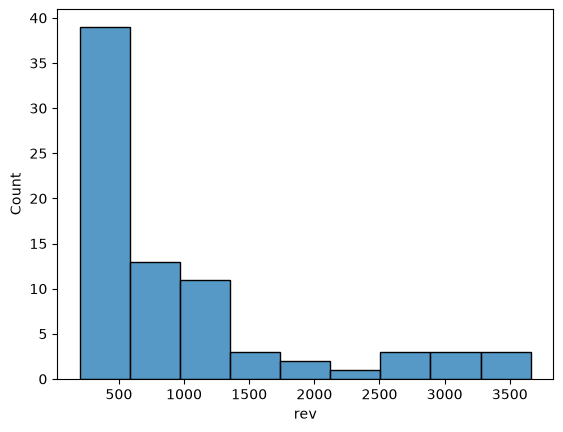

In [24]:
sns.histplot(data=df[df.grp == 'A']['rev'])

<Axes: xlabel='rev', ylabel='Count'>

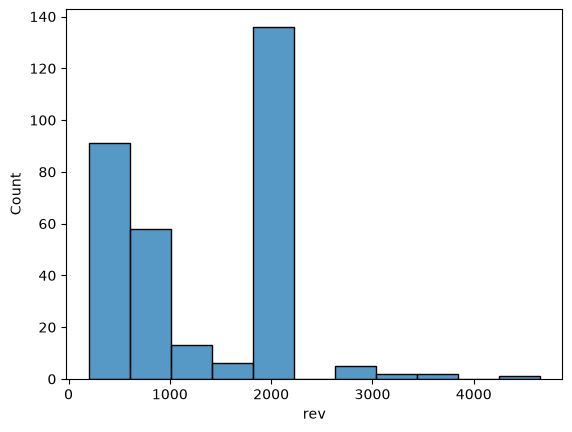

In [25]:
sns.histplot(data=df[df.grp == 'B']['rev'])

<Axes: xlabel='Theoretical quantiles', ylabel='Ordered quantiles'>

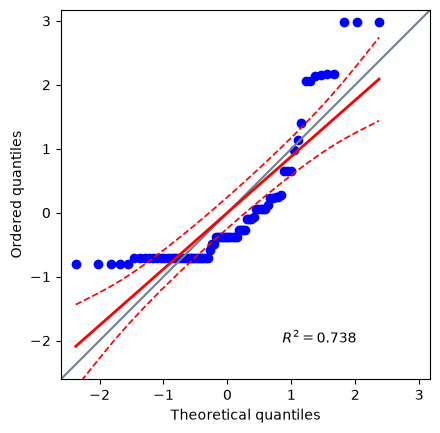

In [26]:
pg.qqplot(df[df.grp == 'A']['rev'])

<Axes: xlabel='Theoretical quantiles', ylabel='Ordered quantiles'>

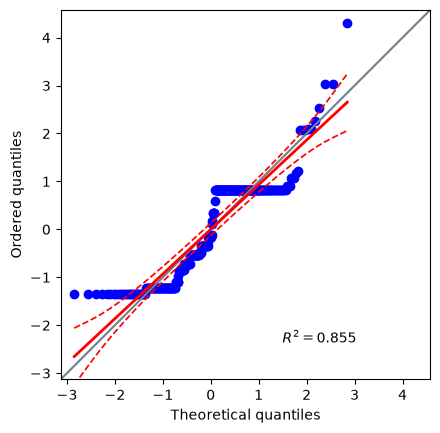

In [27]:
pg.qqplot(df[df.grp == 'B']['rev'])

На графиках наблюдается асимметрия и наличие выбросов, "хвосты" вправо на гистограммах, на qq графиках видно существенное отклонение наблюдаемого распределения от нормального.

Все это является основанием для предположения, что распределение выручки (rev) не является нормальным.
Проверим данное утверждение с помощью `normaltest`.

In [28]:
group_a = df[df.grp == 'A']['rev'].fillna(0)
st.normaltest(group_a)

NormaltestResult(statistic=np.float64(2240.595797407402), pvalue=np.float64(0.0))

In [29]:
group_b = df[df.grp == 'B']['rev'].fillna(0)
st.normaltest(group_b)

NormaltestResult(statistic=np.float64(7797.399211581946), pvalue=np.float64(0.0))

В результате p-value ниже 0.05. Мы отвергаем нулевую гипотезу, т.е. **распределение выручки не является нормальным**, что делает применение параметрических тестов (например, t-test) менее надежным.

## Bootstrap для сравнения средних

Для анализа ARPU и ARPPU используем метод `bootstrap`, так как позволяет оценить доверительный интервал без предположения о нормальности исходного распределения.

In [30]:
# Для ARPU берем всех пользователей, заполняем NaN нулями
group_a_arpu = df[df.grp == 'A']['rev'].fillna(0)
group_b_arpu = df[df.grp == 'B']['rev'].fillna(0)

# Для ARPPU только платящих
group_a_arppu = df[(df.grp == 'A') & (df.paid)]['rev']
group_b_arppu = df[(df.grp == 'B') & (df.paid)]['rev']

In [31]:
# Для оценки разницы между средними двух групп

def bootstrap_mean_diff(data_a, data_b, reps=10000):
    
    boot_diffs = []

    for _ in range(reps):
        sample_a = data_a.sample(frac=1, replace=True).values
        sample_b = data_b.sample(frac=1, replace=True).values
        
        mean_a = sample_a.mean()
        mean_b = sample_b.mean()

        boot_diffs.append(mean_b - mean_a)

    return np.array(boot_diffs)

In [32]:
# Bootstrap для ARPU 

boot_arpu = bootstrap_mean_diff(group_a_arpu, group_b_arpu)

# Считаем 95% доверительный интервал
ci_arpu = np.percentile(boot_arpu, [2.5, 97.5])

# Средняя разница между группами
mean_diff_arpu = boot_arpu.mean()

print('Средняя разница между группами:', mean_diff_arpu)
print('95% доверительный интервал:', ci_arpu)

Средняя разница между группами: 10.758496167984623
95% доверительный интервал: [-5.83020228 26.33939142]


Поскольку доверительный интервал включает 0, **статистически значимых различий в ARPU между группами не обнаружено**.

In [33]:
# Все тоже самое в bootstrap для ARPPU

boot_arppu = bootstrap_mean_diff(group_a_arppu, group_b_arppu)

ci_arppu = np.percentile(boot_arppu, [2.5, 97.5])
mean_diff_arppu = boot_arppu.mean()

print('Средняя разница между группами:', mean_diff_arppu)
print('95% доверительный интервал:', ci_arppu)

Средняя разница между группами: 324.7527958217051
95% доверительный интервал: [ 98.6279123  534.28712291]


Доверительный интервал не включает 0, следовательно, **различия ARPPU статистически значимы**.

## Вывод

В экспериментальной группе наблюдается cнижение CR и увеличение ARPU и ARPPU относительно контрольной группы.

При статистической проверке различие в CR не оказалось значимым. Различие в ARPU также статистически незначимо, тогда как увеличение ARPPU оказалось статистически значимым.

Таким образом, **эксперимент не подтвердил статистически значимого увеличения общей выручки на пользователя**. На основании полученных результатов нет достаточных оснований рекомендовать полный запуск новой механики оплаты на всех пользователей.